In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = pd.read_csv("StudentPerformance.csv")

In [2]:
data["race/ethnicity"] = data["race/ethnicity"].fillna(data["race/ethnicity"].mode()[0])
data["test preparation course"] = data["test preparation course"].fillna(data["test preparation course"].mode()[0])
data["math score"] = pd.to_numeric(data["math score"], errors = "coerce")
data["math score"] = data["math score"].fillna(data["math score"].mean())
data["reading score"] = pd.to_numeric(data["reading score"], errors = "coerce")
data["reading score"] = data["reading score"].fillna(data["reading score"].mean())
data["writing score"] = data["writing score"].fillna(data["writing score"].mean())
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [3]:
data["race/ethnicity"].unique()
data["race/ethnicity"] = data["race/ethnicity"].fillna(
    data["race/ethnicity"].mode()[0]
)

In [4]:
encoder = LabelEncoder()

data["race/ethnicity"] = encoder.fit_transform(data["race/ethnicity"])

In [5]:
x = data[["math score", "reading score", "race/ethnicity"]]
y = data["writing score"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=40
)

In [6]:
Q1 = x_train.quantile(0.25)
Q3 = x_train.quantile(0.75)

IQR = Q3-Q1

lowerLimit = Q1 - 1.5 * IQR
upperLimit = Q3 + 1.5 * IQR           

In [7]:
outlier_mask = (
    (x_train < lowerLimit) |
    (x_train > upperLimit)
).any(axis=1)

print(x_train[outlier_mask])

     math score  reading score  race/ethnicity
601        29.0           29.0               2
466        26.0           31.0               3
787        19.0           38.0               1
145        22.0           39.0               2
810        51.0           31.0               0
980         8.0           24.0               1
59          0.0           17.0               2
17         18.0           32.0               1
327        28.0           23.0               0
76         30.0           26.0               4
338        24.0           38.0               1
596        30.0           24.0               1
211        35.0           28.0               2
842        23.0           44.0               1


In [8]:
x_train_clean = x_train[~outlier_mask]
y_train_clean = y_train.loc[x_train_clean.index]

In [9]:
model = LinearRegression()
model.fit(x_train_clean, y_train_clean)
print("intercept : ", model.intercept_)
print("coefficient : ", model.coef_)

intercept :  -1.022751846005292
coefficient :  [0.05943609 0.93312396 0.22342886]


In [10]:
y_pred = model.predict(x_test)

In [11]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual  Predicted
204    42.0  41.188918
71     63.0  54.713826
594    99.0  98.204622
672    76.0  76.308865
14     58.0  51.404622


In [12]:
print("MAE:", mean_absolute_error(y_test, y_pred))  # mean of absolute error -> |actual - predicted | ->Lower is better
print("MSE:", mean_squared_error(y_test, y_pred)) # large errors contribute more heavily. -> Lower is better
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred))) #Lower is better
print("R2:", r2_score(y_test, y_pred)) #higher is better

MAE: 4.1446418830368055
MSE: 29.307999615086985
RMSE: 5.413686324039007
R2: 0.8713771631041561


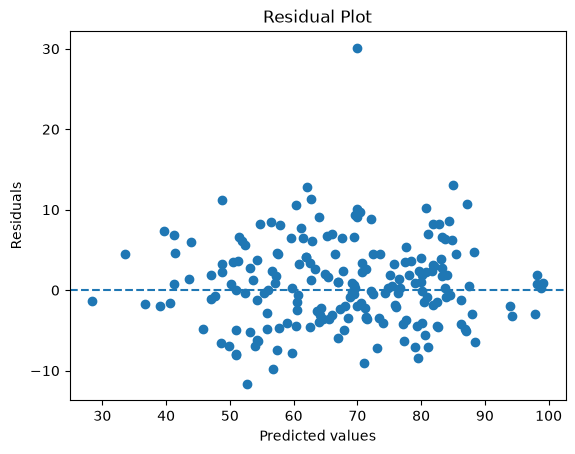

In [13]:
residuals = y_test - y_pred # difference in predictions

plt.scatter(y_pred, residuals) #plot the difference in predictions form actual value, against the predicted value
# good model -> when values are close to zero

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

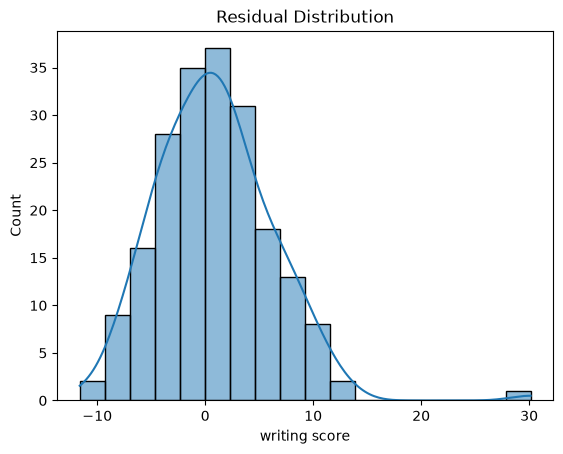

In [14]:
sns.histplot(residuals, kde=True)

plt.title("Residual Distribution")
plt.show()